# Species Distribution Modelling (SDM): Prepare the Datasets

*Section 11 — Case study: species distribution modelling, notebook 1 of 5.* Previous: `10_case_study_icesat2_bathymetry/05_cshelph_bathymetry`. Next: `02_species_distribution_modelling`.

Species distribution modelling is also called habitat suitability modelling. In this case study you will model the distribution of the Snowdon beetle (*Chrysolina cerealis*, also called the rainbow leaf beetle) in Snowdonia (Eryri), Wales. In Britain the beetle is known only from a few mountains of Snowdonia and is now probably confined to small areas of Yr Wyddfa (Snowdon). Both the adults and the larvae feed only on wild thyme (*Thymus polytrichus*), a low, mat-forming plant of free-draining, base-rich soils. On Snowdon, thyme survives best on species-rich rock ledges, crags and scree, where sheep and goats cannot graze it out, and in patches of thyme-rich, base-rich grassland. The Natural Resources Wales (NRW) surveys of 2015–2016 (`../data/sdm/NRW_report_193-Status_Snowdon_Beetle_2016.pdf`) found the beetle only between 555 and 827 m (mean 738 m), and suggest it may be retreating to higher altitudes, possibly because of a warming climate, changes in grazing, or both.

This first notebook prepares the inputs for the models in notebooks 02 (logistic regression), 03 (MaxEnt) and 04 (random forest), which are compared in notebook 05. The choices made here (which records to keep and which environmental variables to offer the model) matter as much as the choice of model, so each step explains why it is done.

**You will learn:**
- how to convert a CSV of species sightings (lat/lon) into a projected vector layer with GeoPandas;
- how to clean species records for their location precision and date, and keep one record per pixel (`rsgispy.vector.geoms.thin_pts_by_raster_grid`);
- how to rasterise a study area and a habitat map (`rsgispy.imageutils.rasterise.rasterise_vec_lyr`);
- how to choose habitat variables from the ecology of the species, rather than giving the model every habitat class;
- how to create distance-to-habitat images (`rsgispy.imagecalc.distance.calc_dist_to_img_vals`) and a valid-data mask (`rsgispy.modelling.species_distribution.create_finite_mask`);
- how to map the results (`rsgispy.mapping.raster`).

**Before you start:** sections 1-3 (`01_getting_started`, `02_making_maps`, `03_vector_data_and_zonal_stats`).

**Data:** `../data/sdm/sightings/Chrysolina_cerealis.csv`, `../data/sdm/environmental_data/` (`Study_Area.geojson`, `Phase1_Veg.geojson`, `Elevation.tif`, `Mean_Winter_Temp.tif`) and `../data/sdm/Phase1-Habitat-DominantSpecies-codes-2008.xlsx`. The outputs are written to `outputs/` and used by the next notebooks.

**Run time:** less than 1 minute.

## 1. Create Vector Sighting Data

 * Import the pandas and geopandas modules needed for this first step.
 * Define the file path to the sighting CSV file
 * Read the CSV file using pandas into a Dataframe
 * Convert Dataframe to a geopandas GeoDataframe - using Lat / Lon (WGS84)
 * Reproject the GeoDataframe to OSGB (EPSG:27700), the projection of the environmental rasters
 * Save as a GeoPackage file which can then be loaded within the GIS

In [1]:
import os

import geopandas
import pandas

out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

In [2]:
sighting_data_csv = "../data/sdm/sightings/Chrysolina_cerealis.csv"

In [3]:
cc_data_df = pandas.read_csv(sighting_data_csv, header=0)
cc_data_df.head()

,Scientific name,Common name,Occurrence status,Year,Latitude (WGS84),Longitude (WGS84),Coordinate uncertainty (m),Recorder,Individual count,Institution code
0,Chrysolina cerealis,Rainbow Leaf Beetle,present,1978.0,53.06999,-4.05370,1000,John Parry,13.0,NRW
1,Chrysolina cerealis,Rainbow Leaf Beetle,present,1902.0,53.06999,-4.05370,1000,J. Chappell,13.0,NRW
2,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08743,-4.08439,1000,Unknown,1.0,NRW
3,Chrysolina cerealis,Rainbow Leaf Beetle,present,2007.0,53.08164,-4.08464,1,Michael Shackshaft,1.0,NRW
4,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08158,-4.08486,100,Adrian Fowles,1.0,NRW


In [4]:
cc_geo_data_gdf = geopandas.GeoDataFrame(
    cc_data_df,
    geometry=geopandas.points_from_xy(
        cc_data_df["Longitude (WGS84)"], cc_data_df["Latitude (WGS84)"]
    ),
    crs="EPSG:4326",
)
cc_geo_osgb_data_gdf = cc_geo_data_gdf.to_crs(epsg=27700)
cc_geo_osgb_data_gdf.to_file(
    os.path.join(out_dir, "Chrysolina_cerealis_osgb.gpkg"),
    layer="Chrysolina_cerealis_osgb",
    driver="GPKG",
)
print(f"{len(cc_geo_osgb_data_gdf)} records")

119 records


## 2. Clean the Species Records

A species distribution model relates each record to the environmental values **of the pixel it falls in**, so every record must be (1) located precisely enough for its pixel to be meaningful and (2) from a time when the environment was like the one the rasters describe. The environmental rasters here have 20 m pixels, and the habitat map describes the vegetation of the 1980s–2000s.

Records of rare species are usually compiled from many sources (museum specimens, naturalists' notes, surveys), so they vary a lot in both respects. The `Coordinate uncertainty (m)` column gives the precision of each location: a record given as a 10 km grid square has an uncertainty of 10 000 m and could be anywhere in a 100 km² square. Let's look at the precision and the dates of the records.

Coordinate uncertainty (m)
1        21
10        1
100      23
1000     55
2000      3
10000    16
Name: count, dtype: int64


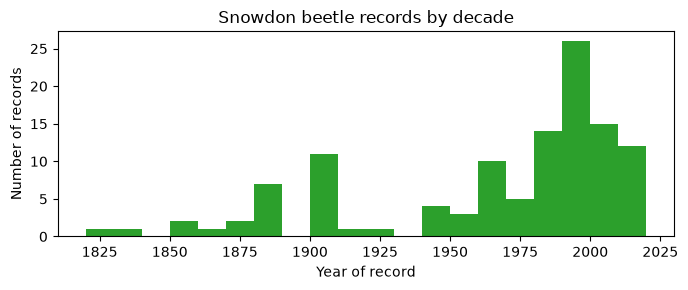

In [5]:
import matplotlib.pyplot as plt

%matplotlib inline

recs_gdf = cc_geo_osgb_data_gdf
print(recs_gdf["Coordinate uncertainty (m)"].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(recs_gdf["Year"].dropna(), bins=range(1820, 2030, 10), color="tab:green")
ax.set_xlabel("Year of record")
ax.set_ylabel("Number of records")
ax.set_title("Snowdon beetle records by decade")
fig.tight_layout()

Only 22 of the 119 records are located to 10 m or better (1 m and 10 m), and 19 are located to 2 km or worse, which is meaningless for 20 m pixels. Records go back to 1829, and only about half are from after 1990.

We apply two cleaning steps:

1. **Location precision.** Drop records with an uncertainty above 1000 m. This is the rule used in the rsgispy species distribution modelling guide, so the tutorial and the guide use the same presences. Be aware that even 1000 m is 50 pixels: those records say little about which pixel the beetle was in.
2. **One record per pixel.** Many records are repeat visits to the same few well-known sites. Several records in one pixel are duplicates as far as the model is concerned, and they would give those sites far more weight than the others. `thin_pts_by_raster_grid` keeps at most one record per pixel of a reference raster (here the 20 m elevation raster). With `prefer_col="Year"` it keeps the **most recent** record in each pixel, the one most likely to reflect current conditions.

In [6]:
import rsgispy.vector.geoms

elevation_img = "../data/sdm/environmental_data/Elevation.tif"

precise_gdf = recs_gdf[recs_gdf["Coordinate uncertainty (m)"] <= 1000]
pres_gdf = rsgispy.vector.geoms.thin_pts_by_raster_grid(
    precise_gdf,
    None,
    elevation_img,
    prefer_col="Year",
    prefer_max=True,
    rnd_seed=42,
)
print(f"All records:                     {len(recs_gdf)}")
print(f"Uncertainty <= 1000 m:           {len(precise_gdf)}")
print(f"One record per 20 m pixel:       {len(pres_gdf)}")
print(pres_gdf["Year"].describe().round(1))
print(pres_gdf["Coordinate uncertainty (m)"].value_counts().sort_index())

All records:                     119
Uncertainty <= 1000 m:           100
One record per 20 m pixel:       34
count      34.0
mean     1997.8
std        14.8
min      1963.0
25%      1990.0
50%      2003.0
75%      2007.0
max      2016.0
Name: Year, dtype: float64
Coordinate uncertainty (m)
1       14
10       1
100     14
1000     5
Name: count, dtype: int64


The 100 records with an uncertainty of 1000 m or better fall in only 34 pixels, so we have **34 presences**. Because the most recent record is kept in each pixel, the presences are much more recent than the raw records (median 2003, earliest 1963), and most are located to 1–100 m; only 5 have an uncertainty of 1000 m.

How sensitive is this to the cleaning rules? The table below shows how many presences remain with stricter rules on precision (100 m) and date (1970 or later, roughly the period of the habitat survey and the climate data).

In [7]:
rows = []
for max_unc in [1000, 100]:
    for min_year in [None, 1970]:
        sel_gdf = recs_gdf[recs_gdf["Coordinate uncertainty (m)"] <= max_unc]
        if min_year is not None:
            sel_gdf = sel_gdf[sel_gdf["Year"] >= min_year]
        thin_gdf = rsgispy.vector.geoms.thin_pts_by_raster_grid(
            sel_gdf, None, elevation_img, prefer_col="Year", rnd_seed=42
        )
        rows.append(
            {
                "max uncertainty (m)": max_unc,
                "from year": min_year if min_year is not None else "all",
                "records": len(sel_gdf),
                "presences (1 per pixel)": len(thin_gdf),
            }
        )
pandas.DataFrame(rows)

,max uncertainty (m),from year,records,presences (1 per pixel)
0,1000,all,100,34
1,1000,1970,67,32
2,100,all,45,29
3,100,1970,44,28


The stricter rules remove only a few presences (28–32 rather than 34), because the most recent, most precise record is already kept in each pixel. We keep the guide's rule (uncertainty ≤ 1000 m) for the rest of this case study. Re-running notebooks 02 and 03 with the stricter presences, and seeing how much the results change, is a good exercise.

Save the cleaned presences, which are used by the next notebooks.

In [8]:
presences_vec_file = os.path.join(out_dir, "Chrysolina_cerealis_presences.gpkg")
presences_vec_lyr = "presences"
pres_gdf[["Year", "Coordinate uncertainty (m)", "geometry"]].to_file(
    presences_vec_file, layer=presences_vec_lyr, driver="GPKG"
)

## 3. Rasterise the Study Site Layer

The elevation image is used as the reference image, defining the projection, extent and pixel size (20 m) of all the images.

The study area (about 170 km² of Snowdonia) defines where pseudo-absences and background points are drawn in the next notebooks, so it is part of the model: it should cover the area the beetle could have reached, not a much larger region.

In [9]:
import rsgispy
import rsgispy.imageutils.rasterise

In [10]:
# Study Site Vector
study_site_vec_file = "../data/sdm/environmental_data/Study_Area.geojson"
study_site_vec_lyr = "Study_Area"

# Output Study Site Image
study_site_img = os.path.join(out_dir, "Study_Area.tif")

# Rasterise the Study Site Layer
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    vec_file=study_site_vec_file,
    vec_lyr=study_site_vec_lyr,
    input_img=elevation_img,
    output_img=study_site_img,
    burn_val=1,
    att_column=None,
    use_vec_extent=False,
    thematic=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=0,
    use_pbar=False,
)

## 4. Rasterise Phase 1 (Vegetation Classification)

https://datamap.gov.wales/layergroups/geonode:nrw_terrestrial_phase_1_habitat_survey

The Phase 1 habitat survey of Wales mapped every parcel of land into one of about 150 habitat classes. The pixel values are taken from the `Class` column of the vector layer (`att_column`), rather than a single burn value.

In [11]:
phase1_vec_file = "../data/sdm/environmental_data/Phase1_Veg.geojson"
phase1_vec_lyr = "Phase1_Veg"

# Output Phase 1 Image
phase1_img = os.path.join(out_dir, "Phase1_Cat.tif")

# Rasterise the Phase 1 Vector layer where the
# pixel values will be from the "Class" column.
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    vec_file=phase1_vec_file,
    vec_lyr=phase1_vec_lyr,
    input_img=elevation_img,
    output_img=phase1_img,
    att_column="Class",
    use_vec_extent=False,
    thematic=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=0,
    use_pbar=False,
)

### 4.1 Create a Phase 1 Habitat Codes and Class Look Up Table

The `Class` values are just integers. We need two look up tables: pixel value → Phase 1 code (from the vector layer), and Phase 1 code → habitat name (from the NRW spreadsheet of Phase 1 codes).

In [12]:
import math

phase1_gdf = geopandas.read_file(phase1_vec_file, layer=phase1_vec_lyr)
phase1_gdf.head()

,Label,Phase1_Cod,Class,geometry
0,"Mosaic of:50% B.1.1,50% E.2.1",mosaic,46.0,"MULTIPOLYGON (((259898.03 353244.91, 259934.94..."
1,"Mosaic of:98% B.1.1,2% E.2.1",mosaic,46.0,"MULTIPOLYGON (((260094.822 352569.765, 259949...."
2,"Mosaic of:98% B.1.1,2% C.2",mosaic,46.0,"MULTIPOLYGON (((260398.56 355776.16, 260409.41..."
3,B.1.1,B.1.1,5.0,"MULTIPOLYGON (((258046.32 352360.501, 257491.3..."
4,B.4,B.4,9.0,"MULTIPOLYGON (((257491.331 352376.345, 257444...."


In [13]:
cls_id_lut = dict()
for index, row in phase1_gdf.iterrows():
    if not math.isnan(row["Class"]):
        cls_id = int(row["Class"])
        if (cls_id > 0) and (cls_id not in cls_id_lut):
            cls_name = row["Phase1_Cod"]
            if cls_name != "NA":
                cls_id_lut[cls_id] = row["Phase1_Cod"]
cls_id_lut

{46: 'mosaic',
 5: 'B.1.1',
 9: 'B.4',
 6: 'B.1.2',
 25: 'E.2.1',
 17: 'D.2',
 32: 'G.2',
 39: 'I.2.2',
 10: 'B.5',
 4: 'A.2.1',
 7: 'B.2.2',
 16: 'D.1.1',
 31: 'G.1',
 43: 'J.3.6',
 1: 'A.1.1.1',
 13: 'C.1.1',
 38: 'I.2.1',
 44: 'J.3.7',
 12: 'B.5.2',
 35: 'I.1.2.1',
 19: 'D.5',
 34: 'I.1.2',
 24: 'E.2',
 42: 'J.1.5',
 40: 'J.1.2',
 41: 'J.1.3',
 3: 'A.1.2.2',
 21: 'E.1.6.1',
 23: 'E.1.8',
 45: 'J.4',
 37: 'I.1.4.1',
 14: 'C.2',
 15: 'C.3.2',
 36: 'I.1.4',
 26: 'E.2.3',
 11: 'B.5.1',
 29: 'E.4',
 18: 'D.3',
 28: 'E.3.2',
 22: 'E.1.7',
 20: 'D.6',
 27: 'E.3',
 30: 'F.1',
 2: 'A.1.1.2',
 8: 'B.3.1',
 33: 'I.1'}

In [14]:
phase1_codes_df = pandas.read_excel(
    "../data/sdm/Phase1-Habitat-DominantSpecies-codes-2008.xlsx",
    sheet_name="Habitat list",
)
cls_names_lut = dict()
for index, row in phase1_codes_df.iterrows():
    cls_name = f"{row['Phase 1 habitat survey of Wales code']}"
    if (cls_name != "" and cls_name != "?" and cls_name.lower() != "nan") and (
        cls_name not in cls_names_lut
    ):
        cls_hab_name = f"{row['Phase 1 habitat survey of Wales name']}"
        if cls_hab_name != "" and cls_hab_name.lower() != "nan":
            cls_names_lut[cls_name] = cls_hab_name
print(f"{len(cls_names_lut)} Phase 1 codes, e.g. C.2: {cls_names_lut['C.2']}")

102 Phase 1 codes, e.g. C.2: Upland species rich ledges


Using these two look up tables we can find the habitat name of any pixel value in the Phase 1 image. Let's try an example:

In [15]:
pixel_val = 14
print(cls_names_lut[cls_id_lut[pixel_val]])

Upland species rich ledges


### 4.2 Add Class Names and a Colour Table to the Phase 1 Image

The Phase 1 image is a thematic (categorical) image. To display it with sensible colours (and a legend) we give each class its habitat name (from the two look up tables above) and a colour (a random colour for each class here) with `set_thematic_classes`, which also marks the image as thematic and calculates the thematic image statistics.

> **RSGISLib users:** rsgispy does not use raster attribute tables (RATs); `set_thematic_classes` stores the class names and colours in the image (read them back with `get_thematic_classes`), replacing `rastergis.set_class_names` and the colour table columns of the RAT.

In [16]:
import numpy
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.stats

rng = numpy.random.default_rng(42)
phase1_classes = dict()
for cls_id in sorted(cls_id_lut):
    phase1_code = cls_id_lut[cls_id]
    # Use the habitat name where there is one, otherwise the Phase 1 code.
    cls_name = cls_names_lut.get(phase1_code, phase1_code)
    cls_clr = [int(v) for v in rng.integers(20, 255, 3)]
    phase1_classes[cls_id] = (cls_name, cls_clr)
rsgispy.imageutils.colourtable.set_thematic_classes(phase1_img, phase1_classes)
print(f"{len(phase1_classes)} classes, e.g. 14: {phase1_classes[14][0]}")

46 classes, e.g. 14: Upland species rich ledges


## 5. Choose the Habitat Variables

The earlier version of this tutorial created a distance image for **every** Phase 1 class (about 45 variables) and gave them all to the model. That is poor practice:

* **Most classes have no plausible link to the beetle** (conifer plantations, buildings, standing water, blanket bog...). Any relationship the model finds with them is either chance or a side effect of where they happen to be (e.g. all low-lying), and it makes the model harder to interpret and to trust.
* **Too many parameters for the data.** With 34 presences, a common rule of thumb (about 10 presences per parameter) allows only 3–4 parameters in a regression model. Even with regularisation, 45 variables invite over-fitting: the model describes the 34 sites, not the species.
* **Collinearity.** The distances to neighbouring habitats are correlated with each other and with elevation, so the importance of a variable is split between its correlated partners, and response curves become uninterpretable.
* **Rare or ubiquitous classes carry no information.** A distance to a class covering half of the study area (acid grassland) is near 0 almost everywhere, whether or not the beetle is there.

Instead, variables should be chosen **a priori, from what is known of the species' ecology**, each with a hypothesis of why it should matter, and then checked statistically for collinearity (notebook 02). This is the approach of the rsgispy species distribution modelling guide.

First, look at how much of the study area each Phase 1 class covers.

In [17]:
import rasterio

with rasterio.open(phase1_img) as src:
    phase1_arr = src.read(1)
    pxl_area_km2 = abs(src.res[0] * src.res[1]) / 1e6
with rasterio.open(study_site_img) as src:
    study_arr = src.read(1)

cls_vals, cls_counts = numpy.unique(phase1_arr[study_arr == 1], return_counts=True)
area_df = pandas.DataFrame(
    {
        "pixel value": cls_vals,
        "code": [cls_id_lut.get(int(v), "unmapped / NA") for v in cls_vals],
        "area (km²)": (cls_counts * pxl_area_km2).round(3),
    }
)
area_df["habitat"] = [cls_names_lut.get(code, code) for code in area_df["code"]]
area_df = area_df[area_df["pixel value"] > 0].sort_values("area (km²)", ascending=False)
print(f"Study area: {study_arr.sum() * pxl_area_km2:.1f} km²")
area_df.head(10)

Study area: 170.3 km²


,pixel value,code,area (km²),habitat
5,5,B.1.1,49.492,Unimproved acid grassland
46,46,mosaic,43.279,mosaic
16,16,D.1.1,18.503,Dry acid heath
19,19,D.5,5.995,Wet heath/acid grassland mosaic
6,6,B.1.2,4.878,Semi-improved acid grassland
9,9,B.4,4.379,Improved grassland
25,25,E.2.1,4.118,Acid/neutral flush
13,13,C.1.1,3.533,Bracken
3,3,A.1.2.2,3.276,Planted coniferous woodland
22,22,E.1.7,2.877,Wet modified bog


Unimproved acid grassland (B.1.1) and the mapped "mosaic" class (areas too intimately mixed to map separately, with no single habitat meaning) together cover over half of the study area. The habitats most relevant to the beetle are small: there is only about 1 km² of upland species-rich ledges (C.2).

We group the Phase 1 classes into six habitat variables, each with an ecological hypothesis. The groups are defined by **Phase 1 code**, and the pixel values are looked up from `cls_id_lut`, so they are not hard-coded:

| Variable | Phase 1 codes | Hypothesis |
| --- | --- | --- |
| `ledges_dist` | C.2 upland species-rich ledges | The core habitat: base-rich ledges with thyme, out of reach of sheep and goats. Expected: suitability falls with distance. |
| `calc_grass_dist` | B.3.1 unimproved calcareous grassland, D.6 basic dry heath / calcareous grassland mosaic | Base-rich, free-draining swards where thyme is common (the historic records come from thyme-rich grassland). Expected: falls with distance. |
| `rock_dist` | I.1 natural rock exposure, I.1.4 other rock exposure, I.1.4.1 acid/neutral rock | Crags and outcrops: ungrazed refuges for thyme, and the setting of the recent records. Expected: falls with distance. |
| `scree_dist` | I.1.2 scree, I.1.2.1 acid/neutral scree | Free-draining, lightly grazed ground at the foot of crags, where thyme grows at the scree margins. Expected: falls with distance. |
| `flush_dist` | E.2 flush and spring, E.2.1 acid/neutral flush | **Exploratory.** Thyme does not grow in wet flushes, but on Snowdon's crags flushes mark seepage from base-rich volcanic rocks next to the ledge flora. Most mapped flushes are acid/neutral (E.2.1), so the base-rich link is weak: if this variable matters, it more likely marks the crag complex than a need of the beetle. |
| `impr_grass_dist` | B.4 improved grassland | A contrast: fertilised, heavily grazed lowland pasture with no thyme. Expected: suitability **rises** with distance (avoidance). |

Other classes are left out:

* woodland, scrub and plantations (A.\*), bracken (C.1.1), bogs, mires and fens (E.1.\*, E.3\*, E.4), swamp (F.1), water (G.\*), quarries and spoil (I.2.\*) and built land (J.\*): no hypothesised link to thyme or the beetle;
* acid grassland, heath and marshy grassland (B.1\*, B.5\*, D.1–D.5): acidic and/or wet, and so extensive that distance to them carries no information;
* "mosaic" and unmapped ("NA"): no single habitat meaning.

The two climate/terrain rasters, **elevation** and **mean winter temperature**, are also kept as candidates; they are strongly correlated, and the choice between them is made in notebook 02.

In [18]:
habitat_groups = {
    "ledges_dist": ["C.2"],
    "calc_grass_dist": ["B.3.1", "D.6"],
    "rock_dist": ["I.1", "I.1.4", "I.1.4.1"],
    "scree_dist": ["I.1.2", "I.1.2.1"],
    "flush_dist": ["E.2", "E.2.1"],
    "impr_grass_dist": ["B.4"],
}
code_to_pxl = {code: pxl for pxl, code in cls_id_lut.items()}
habitat_pxl_vals = {
    var: [code_to_pxl[code] for code in codes] for var, codes in habitat_groups.items()
}
habitat_pxl_vals

{'ledges_dist': [14],
 'calc_grass_dist': [8, 20],
 'rock_dist': [33, 36, 37],
 'scree_dist': [34, 35],
 'flush_dist': [24, 25],
 'impr_grass_dist': [9]}

**A caveat: habitats hidden in mosaics.** The "mosaic" polygons are not featureless: their `Label` lists the habitats they contain and their proportions (e.g. `Mosaic of:98% B.1.1,2% C.2`). Habitats such as ledges and scree, which occur as small patches among grassland, are often mapped only as part of a mosaic. The next cell estimates how much of each habitat group is "hidden" in this way (polygon area × proportion).

In [19]:
import re

mosaic_gdf = phase1_gdf[phase1_gdf["Phase1_Cod"] == "mosaic"].to_crs(epsg=27700)
mosaic_km2 = mosaic_gdf.geometry.area / 1e6
hidden_rows = []
for var_name, codes in habitat_groups.items():
    hidden_km2 = 0.0
    for code in codes:
        pct = mosaic_gdf["Label"].str.extract(rf"(\d+)% {re.escape(code)}(?=,|$)")[0]
        hidden_km2 += float((mosaic_km2 * pct.astype(float).fillna(0) / 100).sum())
    hidden_rows.append(
        {
            "variable": var_name,
            "mapped as the class (km²)": area_df.loc[
                area_df["code"].isin(codes), "area (km²)"
            ].sum(),
            "within mosaics (km², approx.)": round(hidden_km2, 2),
        }
    )
pandas.DataFrame(hidden_rows)

,variable,mapped as the class (km²),"within mosaics (km², approx.)"
0,ledges_dist,1.013,0.41
1,calc_grass_dist,1.422,0.13
2,rock_dist,0.441,0.11
3,scree_dist,2.990,1.89
4,flush_dist,4.147,5.14
5,impr_grass_dist,4.379,0.00


About 0.4 km² of species-rich ledges (40 % more than the 1.0 km² mapped as ledges), 1.9 km² of scree and more flushes than are mapped as flushes are hidden in mosaic polygons. The distance images below use only the polygons mapped as each class, so they understate these habitats: a beetle recorded on a small ledge inside a mosaic polygon appears to be some distance from the nearest "ledge". We cannot tell where in a mosaic polygon its habitats are, so we accept this limitation (it adds noise and weakens the relationships the models can find). A possible extension is to count mosaic polygons with, say, 25 % or more of a habitat as that habitat.

A table of every class, whether it is used and in which variable:

In [20]:
code_to_var = {code: var for var, codes in habitat_groups.items() for code in codes}
area_df["variable"] = [code_to_var.get(code, "—") for code in area_df["code"]]
pandas.set_option("display.max_rows", 60)
area_df.sort_values("code").reset_index(drop=True)

,pixel value,code,area (km²),habitat,variable
0,1,A.1.1.1,2.092,Semi-natural broadleaved woodland,—
1,2,A.1.1.2,0.016,Planted broadleaved woodland,—
2,3,A.1.2.2,3.276,Planted coniferous woodland,—
3,4,A.2.1,0.154,Dense scrub,—
4,5,B.1.1,49.492,Unimproved acid grassland,—
5,6,B.1.2,4.878,Semi-improved acid grassland,—
6,7,B.2.2,0.093,Semi-improved neutral grassland,—
7,8,B.3.1,0.056,Unimproved calcareous grassland,calc_grass_dist
8,9,B.4,4.379,Improved grassland,impr_grass_dist
9,10,B.5,2.012,Marshy grassland,—


## 6. Create the Habitat Distance Images

Why distances rather than the habitat class of the record's pixel?

* **Positional error.** A record located to 100 m could be in any of about 80 pixels; the class of the one pixel it falls in may not be the habitat the beetle was in.
* **Map generalisation.** A Phase 1 polygon is the dominant habitat of a parcel; small ledges and thyme patches inside a crag or grassland polygon are not mapped separately.
* **Use of the surroundings.** A beetle on a patch of thyme in a grassland next to a ledge depends on the ledge being near, not on the pixel being mapped as a ledge.

So, for every pixel, we calculate the distance (in metres) to the nearest pixel of each habitat group. A **small** distance to a **rare** habitat (ledges) is informative; distance to a habitat that is everywhere is not, which is another reason for the selection above.

`calc_dist_to_img_vals` calculates, for every pixel, the distance (in map units, i.e. metres, as `unit_geo=True`) to the nearest pixel with one of the values in `pxl_vals`.

**Should the distances be transformed?** Distances of several kilometres are not ecologically different for a beetle that is thought to be flightless (NRW report), and a logarithm (`log1p`) or a cap would reflect that. We keep the distances in metres, untransformed, in all the models: the logistic link of the logistic regression already turns a linear term into an S-shaped decline, MaxEnt's hinge features can fit a steep decline near the habitat and a flat response beyond it, a random forest is unaffected by monotonic transformations of a variable, and response curves in metres are directly interpretable. Notebook 02 checks whether the fitted responses are sensible.

In [21]:
import rsgispy.imagecalc.distance
import rsgispy.imageutils.stats

phase1_dist_dir = os.path.join(out_dir, "phase1_dist_imgs")
os.makedirs(phase1_dist_dir, exist_ok=True)

habitat_imgs = dict()
for var_name, pxl_vals in habitat_pxl_vals.items():
    dist_img = os.path.join(phase1_dist_dir, f"{var_name}.tif")
    rsgispy.imagecalc.distance.calc_dist_to_img_vals(
        phase1_img,
        dist_img,
        pxl_vals=pxl_vals,
        img_band=1,
        max_dist=None,
        unit_geo=True,
        gdalformat="GTIFF",
        no_data_val=None,
        out_no_data_val=-9999,
        use_pbar=False,
    )
    rsgispy.imageutils.stats.pop_img_stats(
        dist_img, no_data_val=-9999, calc_pyramids=True, use_pbar=False
    )
    habitat_imgs[var_name] = dist_img
habitat_imgs

{'ledges_dist': 'outputs/phase1_dist_imgs/ledges_dist.tif',
 'calc_grass_dist': 'outputs/phase1_dist_imgs/calc_grass_dist.tif',
 'rock_dist': 'outputs/phase1_dist_imgs/rock_dist.tif',
 'scree_dist': 'outputs/phase1_dist_imgs/scree_dist.tif',
 'flush_dist': 'outputs/phase1_dist_imgs/flush_dist.tif',
 'impr_grass_dist': 'outputs/phase1_dist_imgs/impr_grass_dist.tif'}

## 7. Define the Candidate Environmental Variables and a Valid-Data Mask

The models in notebooks 02–04 read the candidate variables from a small JSON file, so all the notebooks use the same names and files.

Pixels inside the study area can still have missing data in one of the rasters (the elevation and temperature rasters use 0 as their no data value). `create_finite_mask` writes a mask that is 1 only where the pixel is in the study area **and** every variable has a valid value. The pseudo-absences, background points and predictions of the next notebooks use this mask, so they never land on missing data.

In [22]:
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio

winter_temp_img = "../data/sdm/environmental_data/Mean_Winter_Temp.tif"
cand_var_imgs = {"elevation": elevation_img, "winter_temp": winter_temp_img}
cand_var_imgs.update(habitat_imgs)
rsgispy.tools.jsonio.write_dict_to_json(
    cand_var_imgs, os.path.join(out_dir, "sdm_candidate_vars.json")
)

env_vars = {
    name: species_distribution.EnvVarInfo(
        name=name, file=img, band=1, data_type=rsgispy.VAR_TYPE_CONTINUOUS
    )
    for name, img in cand_var_imgs.items()
}
valid_msk_img = os.path.join(out_dir, "valid_mask.tif")
species_distribution.create_finite_mask(
    study_site_img, 1, env_vars, list(env_vars), valid_msk_img, use_pbar=False
)
with rasterio.open(valid_msk_img) as src:
    n_valid = int((src.read(1) == 1).sum())
print(f"Valid area: {n_valid * pxl_area_km2:.1f} km² ({n_valid} pixels)")

Valid area: 170.2 km² (425449 pixels)


## 8. Make Some Maps

You will probably want to open the data within QGIS or similar to visualise the data but within the notebook we'll create some maps to see what the data looks like.

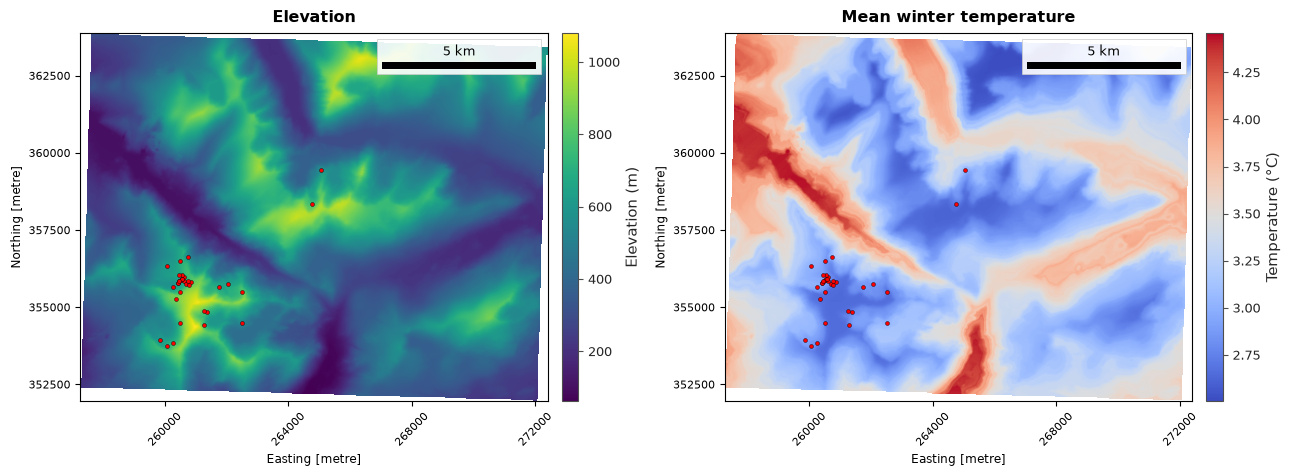

In [23]:
import rsgispy.mapping.raster

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
rsgispy.mapping.raster.create_raster_cmap_img_map(
    axs[0],
    input_img=elevation_img,
    img_band=1,
    title_str="Elevation",
    show_colour_bar=True,
    cbar_label="Elevation (m)",
)
rsgispy.mapping.raster.create_raster_cmap_img_map(
    axs[1],
    input_img=winter_temp_img,
    img_band=1,
    title_str="Mean winter temperature",
    cmap_name="coolwarm",
    show_colour_bar=True,
    cbar_label="Temperature (°C)",
)
for ax in axs:
    pres_gdf.plot(ax=ax, color="red", markersize=8, edgecolor="black", linewidth=0.3)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

The presences (red) are concentrated on the high ground around Yr Wyddfa, in the south-west of the study area, with a few elsewhere. Mean winter temperature is almost a mirror image of elevation (it falls as you go up), so in this study area the two are close to interchangeable.

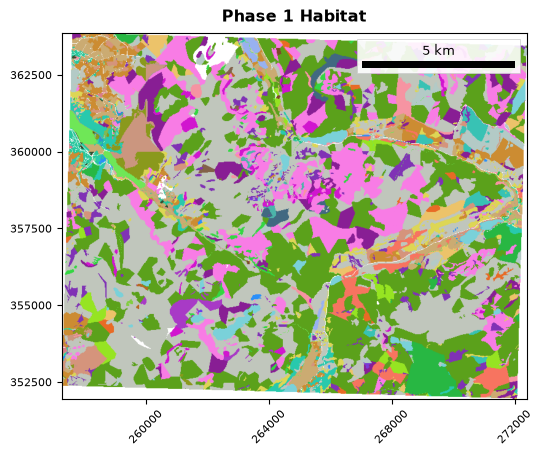

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
rsgispy.mapping.raster.create_thematic_raster_map(
    ax,
    input_img=phase1_img,
    title_str="Phase 1 Habitat",
)
ax.tick_params(axis="x", labelrotation=45)

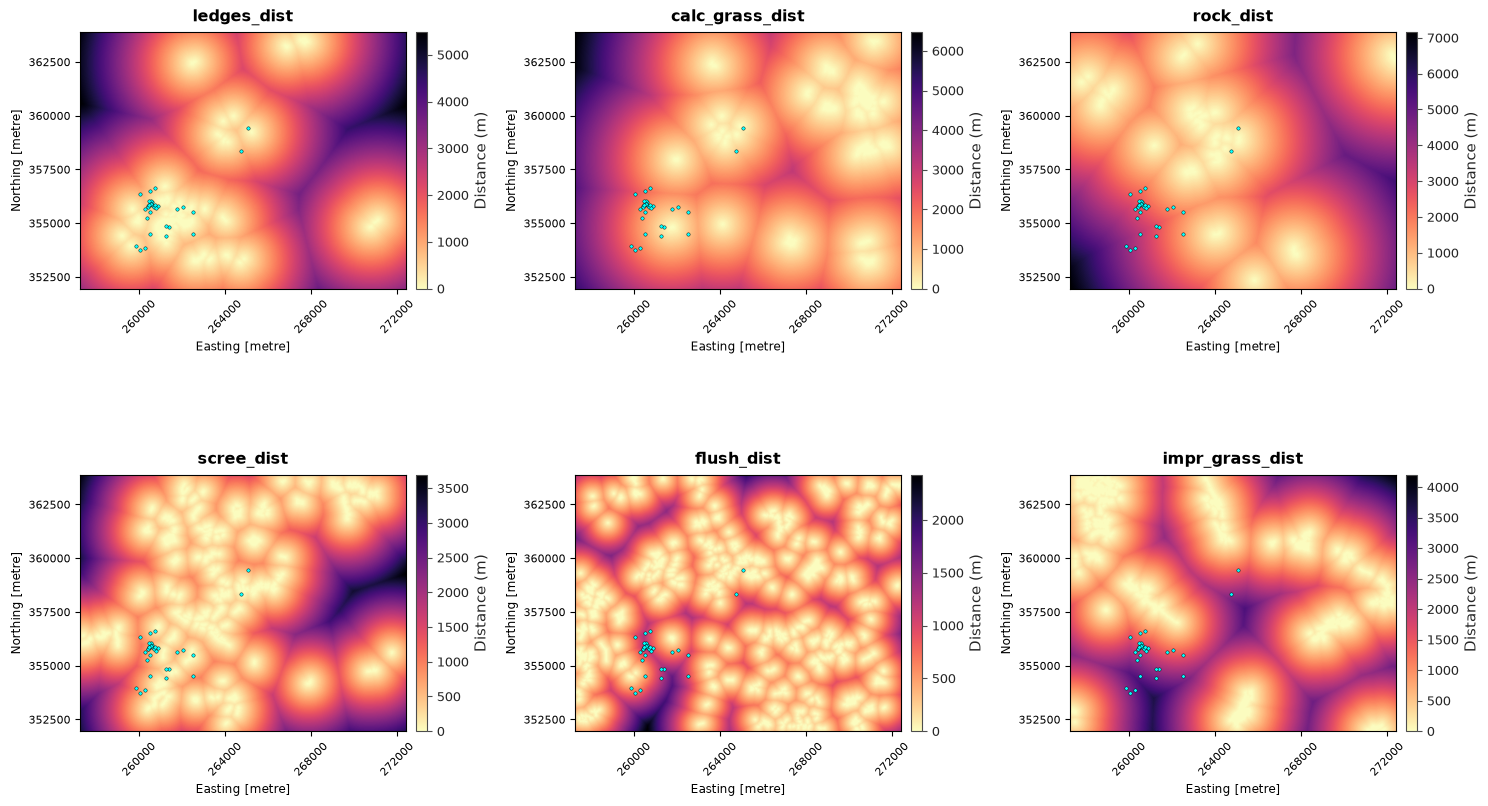

In [25]:
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, (var_name, dist_img) in zip(axs.flatten(), habitat_imgs.items()):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax,
        input_img=dist_img,
        img_band=1,
        title_str=var_name,
        cmap_name="magma_r",
        show_colour_bar=True,
        cbar_label="Distance (m)",
        show_scale_bar=False,
    )
    pres_gdf.plot(ax=ax, color="cyan", markersize=6, edgecolor="black", linewidth=0.3)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

Most presences are within a few hundred metres of mapped species-rich ledges and scree, on the high ground around Yr Wyddfa. Rock exposures and calcareous grassland are mapped as scattered patches, and several presences are over 1 km from them. Flushes are mapped almost everywhere (acid/neutral flushes cover 4 km²), so the distance to a flush is small nearly everywhere, which already suggests it will carry little information. Improved grassland is in the valleys. Notebook 02 compares the values at the presences with the rest of the study area, and checks how strongly these variables are correlated with each other and with elevation and temperature, before fitting a model.